In [1]:
import matplotlib.pyplot as plt
from einops import rearrange
import numpy as np
import pickle
import torch
import math
import sys

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.fourier import isotropic_power_spectrum
from waveletflux.utils.plot import draw_movie, plot_psd
from waveletflux.utils.eval import build_stats_df

well_dataset_name = 'turbulent_radiative_layer_2D'

RESULT_DIR = f"/Users/gabrieleaccarino/Workspace/waveletflux/experiments/{well_dataset_name}/results"

In [3]:
model_paths = {
    "WaveletFM-1scale"  : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales" : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"       : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    "UNetConvNext"      : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
}

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)


In [5]:
print(rollout_traj['WaveletFM-1scale'].shape)
print(rollout_traj['WaveletFM-3scales'].shape)
print(rollout_traj['UNetClassic'].shape)
print(rollout_traj['UNetConvNext'].shape)
print(truth_traj.shape)

torch.Size([9, 1, 101, 128, 384, 4])
torch.Size([9, 1, 101, 128, 384, 4])
torch.Size([9, 101, 128, 384, 4])
torch.Size([9, 101, 128, 384, 4])
torch.Size([9, 101, 128, 384, 4])


# Benchmark Plot across Rollout Steps

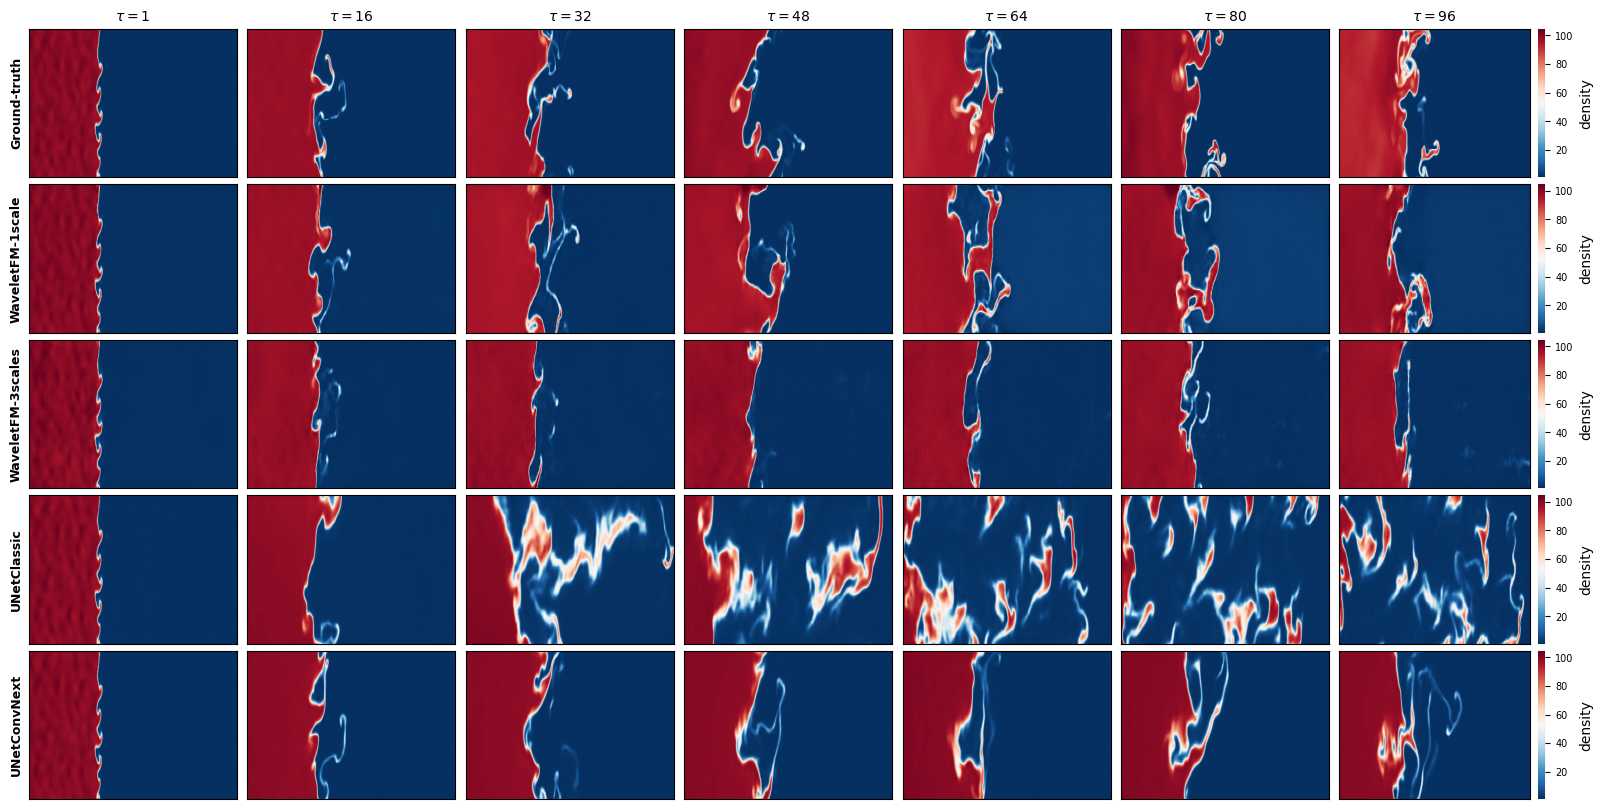

In [6]:
models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales", "UNetClassic", "UNetConvNext"]
field_names    = ['density', 'pressure', 'velocity_x', 'velocity_y']

# ── Config ─────────────────────────────────────────────────────────────────────
TRAJ_IDX   = 5
ENS_IDX    = 0
Ti         = 4
field_idx  = 0
field_name = field_names[field_idx]
lead_times = [1, 16, 32, 48, 64, 80, 96]

# ── Frame helpers ──────────────────────────────────────────────────────────────
def get_gt_frame(tensor, traj_idx, lead, field):
    """
    tensor    : (N_TRAJ, rollout_steps, H, W, C)
    traj_idx  : trajectory index
    lead      : 1-indexed rollout step
             lead=1 → physical frame Ti+1, i.e. tensor[Ti + lead - 1]
    """
    return tensor[traj_idx, Ti + lead - 1, :, :, field]   

def get_pred_frame(tensor, traj_idx, ens_idx, lead, field):
    """
    tensor    : (N_TRAJ, N_ENSEMBLE, rollout_steps, H, W, C)
    traj_idx  : trajectory index
    ens_idx   : ensemble index
    lead      : 1-indexed rollout step → index = lead - 1
    """
    if len(tensor.shape) == 6:
        return tensor[traj_idx, ens_idx, lead - 1, :, :, field]
    return tensor[traj_idx, lead - 1, :, :, field]

# ── Results dict ───────────────────────────────────────────────────────────────

# ── Frames ─────────────────────────────────────────────────────────────────────
gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot
}

vmin = min(f.min() for f in gt_frames)
vmax = max(f.max() for f in gt_frames)

# ── Layout ─────────────────────────────────────────────────────────────────────
row_labels     = ["Ground-truth"] + models_to_plot
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot]
n_rows, n_cols = len(row_labels), len(lead_times)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.8 * n_cols, 2.0 * n_rows),
    gridspec_kw={"hspace": 0.05, "wspace": 0.05},
)
if n_rows == 1:
    axes = axes[None, :]

for ri, (frames, label) in enumerate(zip(all_row_frames, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        im = ax.imshow(frames[ci], origin="lower", cmap="RdBu_r",
                       vmin=vmin, vmax=vmax, aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=10, fontweight="bold")

    plt.rcParams["axes.linewidth"] = 0.02
    cbar = fig.colorbar(im, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    cbar.ax.tick_params(labelsize=7)

plt.show()

# Draw Movie

In [13]:
truth_traj.shape, rollout_traj['WaveletFM-1scale'].shape

(torch.Size([9, 101, 128, 384, 4]), torch.Size([9, 1, 101, 128, 384, 4]))

## Baseline(s) vs GT

In [7]:
TRAJ_IDX = 5

x_gt  = truth_traj[TRAJ_IDX, Ti:, ...]
x_hat = rollout_traj['UNetClassic'][TRAJ_IDX, :-Ti, ...]

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

## WaveletFM vs GT

In [9]:
TRAJ_IDX = 5

x_gt  = truth_traj[TRAJ_IDX, Ti:, ...]
x_hat = rollout_traj['WaveletFM-1scale'][TRAJ_IDX, 0, :-Ti, ...]
#x_hat = rollout_traj['WaveletFM-3scales'][TRAJ_IDX, 0, :-Ti, ...]

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

# Plot PSD

In [56]:
x_gt.shape

torch.Size([97, 128, 384, 4])

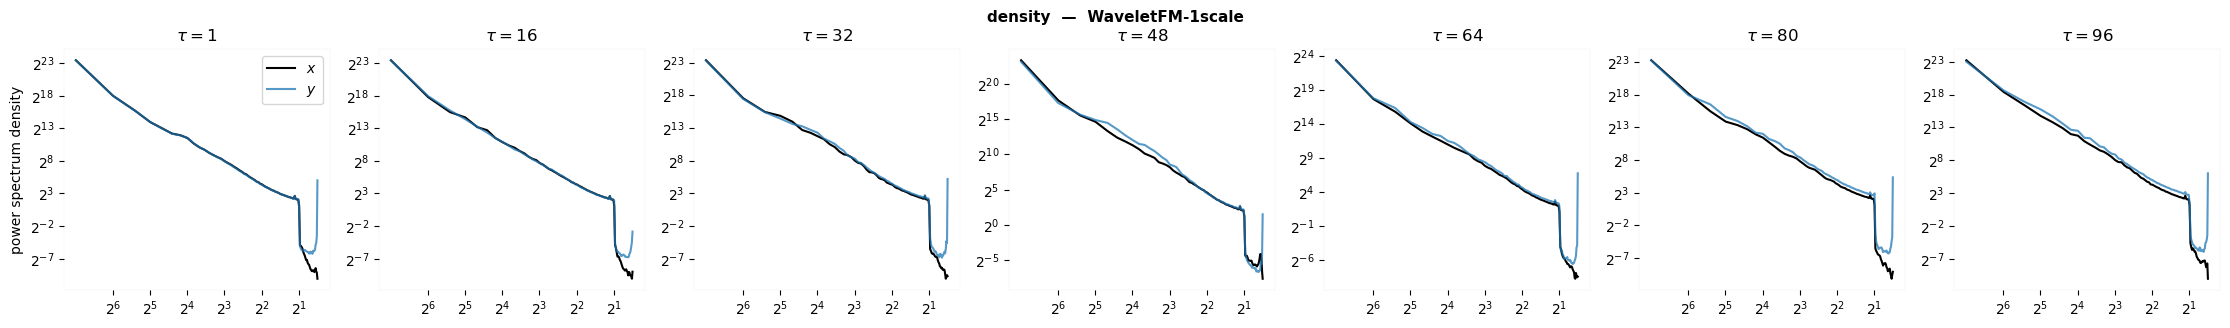

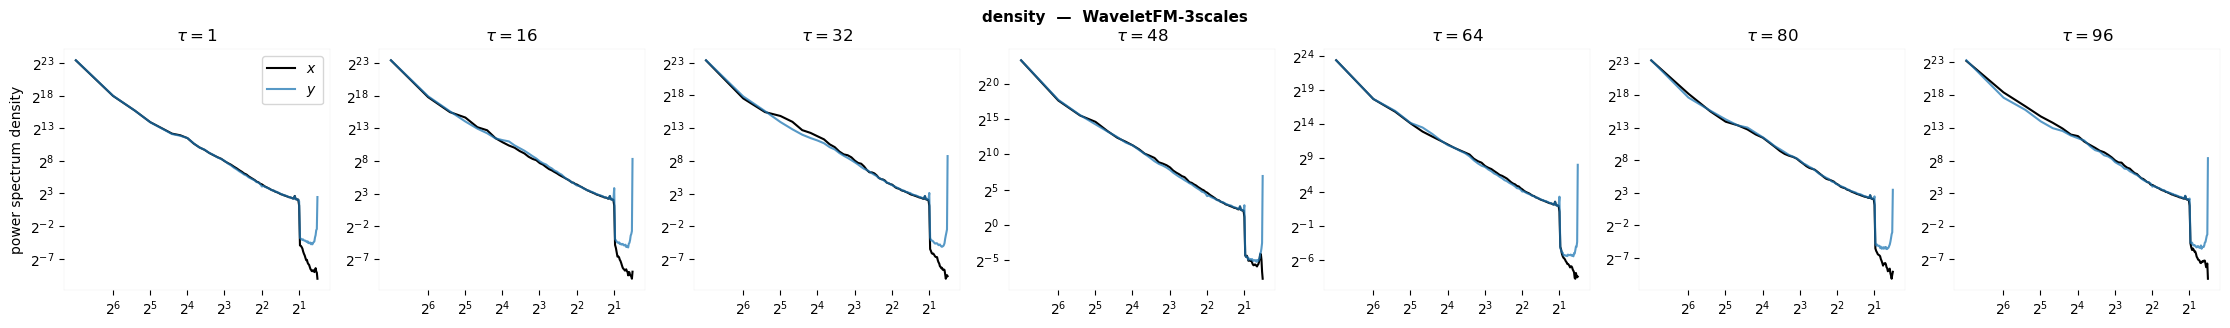

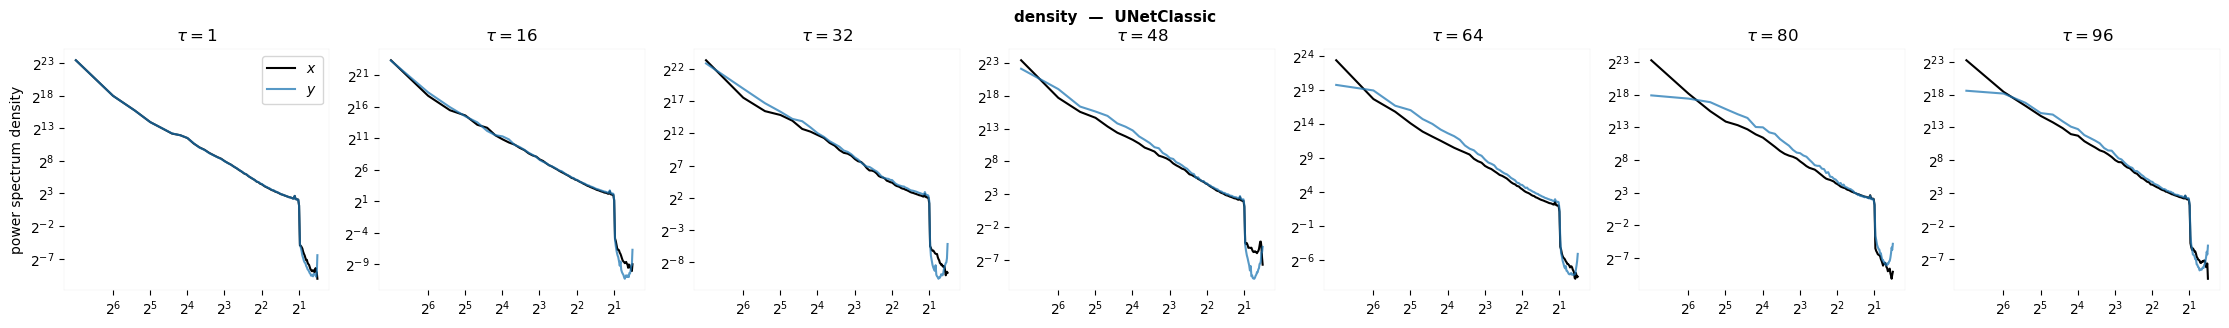

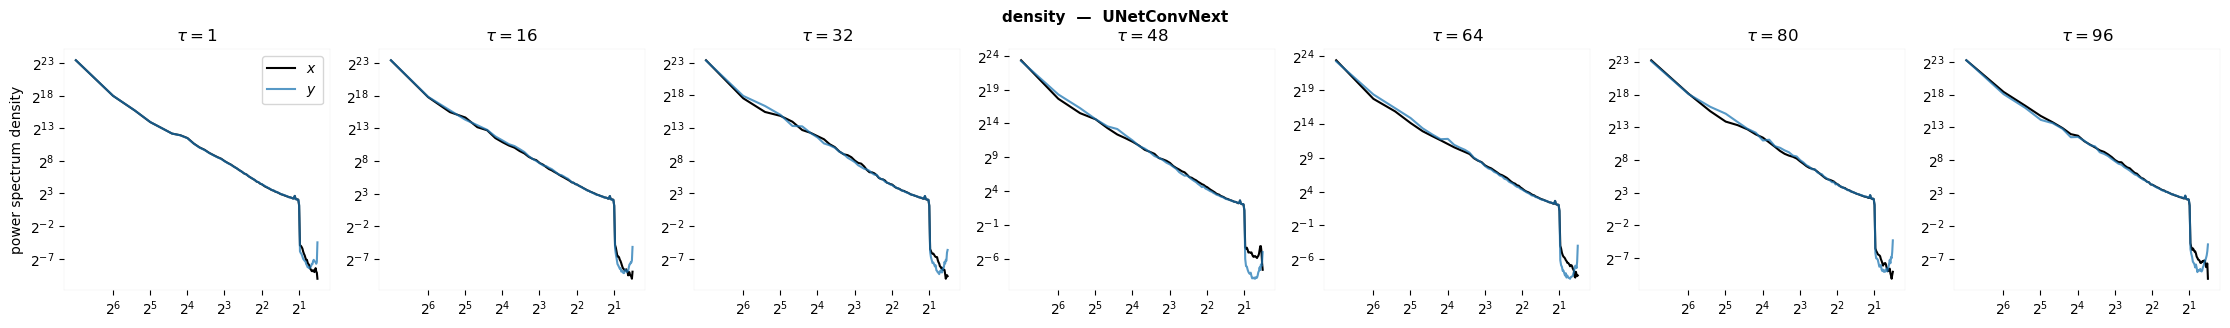

In [64]:
# ── Stack frames: (n_lead_times, H, W) ────────────────────────────────────────
# plot_psd expects (C, ...) — we use lead times as the "channel" dimension

gt_stacked = np.stack([np.asarray(f) for f in gt_frames], axis=0)
# shape: (n_lead_times, H, W)

psd_fields = [rf"$\tau={t}$" for t in lead_times]

# ── One PSD figure per model ───────────────────────────────────────────────────
for name in models_to_plot:
    model_stacked = np.stack([np.asarray(f) for f in model_frames[name]], axis=0)
    # shape: (n_lead_times, H, W)

    fig = plot_psd(
        x=gt_stacked,        # reference (GT), labeled "$x$" in the legend
        y=model_stacked,     # prediction, labeled "$y$" in the legend
        fields=psd_fields,   # subplot title per lead time
        figsize=(3.2, 3.2),
    )
    fig.suptitle(f"{field_name}  —  {name}", fontsize=11, fontweight="bold", y=1.01)
    fig.savefig(f"psd_{field_name}_{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

In [74]:
lead_times

[1, 16, 32, 48, 64, 80, 96]

# Power Spectrum RMSE

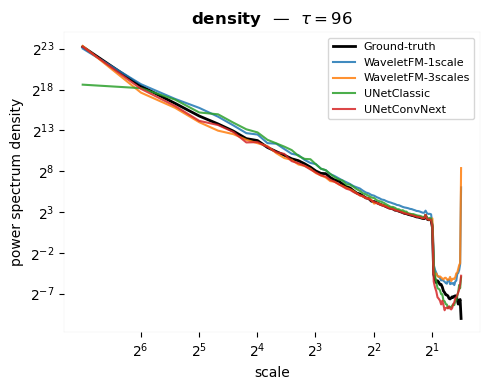

In [73]:
# Pick a single lead time to compare across all models
LEAD_IDX = 6   # e.g. lead_times[3] = 48

fig, axs = plt.subplots(1, 1, figsize=(5, 4))

gt_frame = np.asarray(gt_frames[LEAD_IDX])
p_gt, k = isotropic_power_spectrum(gt_frame[None], spatial=2)
axs.loglog(1 / k, p_gt.squeeze(), base=2, label="Ground-truth", color="black", linewidth=2)

colors = plt.cm.tab10.colors
for ci, name in enumerate(models_to_plot):
    frame = np.asarray(model_frames[name][LEAD_IDX])
    p_m, _ = isotropic_power_spectrum(frame[None], spatial=2)
    axs.loglog(1 / k, p_m.squeeze(), base=2, label=name, color=colors[ci], alpha=0.85)

axs.invert_xaxis()
axs.set_xticks([2**i for i in range(1, math.ceil(math.log2(1 / k[0].item())))])
axs.set_xlabel("wavelength ")
axs.set_ylabel("power spectrum density")
axs.set_title(rf"{field_name}  —  $\tau={lead_times[LEAD_IDX]}$", fontweight="bold")
axs.legend(fontsize=8)
fig.tight_layout()
plt.show()

# STATS

In [ ]:
# ── Assemble predictions dict ─────────────────────────────────────────────────
# Generative models: (N_TRAJ, N_ENS, STEPS, H, W, C)
# Baselines:         (N_TRAJ,        STEPS, H, W, C)  — automatically detected via ndim

predictions = {
    "WaveletFM-1scale":  rollout_traj["WaveletFM-1scale"][:, :, :-Ti, ...],   # (N_TRAJ, N_ENS, STEPS, H, W, C)
    "WaveletFM-3scales": rollout_traj["WaveletFM-3scales"][:, :, :-Ti, ...],  # (N_TRAJ, N_ENS, STEPS, H, W, C)
    "UNetClassic":       rollout_traj["UNetClassic"][:, :-Ti, ...],           # (N_TRAJ,        STEPS, H, W, C)
    "UNetConvNext":      rollout_traj["UNetConvNext"][:, :-Ti, ...],          # (N_TRAJ,        STEPS, H, W, C)
}

df = build_stats_df(
    truth        =  truth_traj[:, Ti:, ...],
    predictions  = predictions,
    field_names  = field_names,
    lead_times   = np.arange(97), # TODO : replace with actual lead times (lead_times)
    stride       = 1,
)


In [109]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .mean()
    .round(4)
)
print(summary.to_string())

                               vrmse  rmse_p_low  rmse_p_mid  rmse_p_high
model             field                                                  
UNetClassic       density     0.6905      0.4928      0.6300       0.2467
                  pressure    2.7890     15.5413      6.1723       2.7366
                  velocity_x  1.2228      0.6483      0.5059       0.3165
                  velocity_y  1.3294      2.0915      1.2852       1.5355
UNetConvNext      density     0.4171      0.2261      0.2610       0.1552
                  pressure    2.5643      1.3102      0.7934       0.4344
                  velocity_x  0.5024      0.3533      0.4114       0.1804
                  velocity_y  1.0013      0.8606      0.6840       0.4387
WaveletFM-1scale  density     0.4271      0.2269      0.2802       0.1615
                  pressure    1.5892      1.1516      0.7362       0.3563
                  velocity_x  0.4876      0.3428      0.4056       0.1777
                  velocity_y  0.9477  

In [110]:
df

,model,traj,field,lead_time,time,m1,m2,spread,rmse,nrmse,vrmse,spread_skill,total_error,rmse_p_low,rmse_c_low,rmse_p_mid,rmse_c_mid,rmse_p_high,rmse_c_high
0,WaveletFM-1scale,0,density,0,0,38.535141,2977.063477,NaN,20.459715,0.374978,0.529658,NaN,0.021463,0.402972,0.207092,0.297114,0.160761,0.371040,0.140910
1,WaveletFM-1scale,0,density,1,1,34.033676,3266.291748,NaN,1.294484,0.022650,0.028194,NaN,-0.005837,0.001678,0.000038,0.017358,0.002529,0.039588,0.023327
2,WaveletFM-1scale,0,density,2,2,34.048298,3247.458984,NaN,1.896554,0.033281,0.041503,NaN,-0.001002,0.008031,0.000037,0.020478,0.007821,0.059954,0.033847
3,WaveletFM-1scale,0,density,3,3,34.063934,3227.473877,NaN,2.742202,0.048269,0.060313,NaN,0.000925,0.010143,0.000265,0.025573,0.019474,0.045121,0.043753
4,WaveletFM-1scale,0,density,4,4,34.080036,3207.958740,NaN,3.534292,0.062401,0.078125,NaN,0.000867,0.012371,0.000405,0.041188,0.030078,0.048381,0.059611
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13963,UNetConvNext,8,velocity_y,92,92,-0.004313,0.000106,NaN,0.011494,1.112188,1.223867,NaN,0.052509,0.231688,0.063912,0.341061,0.196488,0.145169,0.127515
13964,UNetConvNext,8,velocity_y,93,93,-0.004179,0.000112,NaN,0.012346,1.161609,1.263330,NaN,0.070891,0.308361,0.074447,0.359232,0.197336,0.139184,0.134724
13965,UNetConvNext,8,velocity_y,94,94,-0.003894,0.000125,NaN,0.013121,1.167865,1.245022,NaN,0.048381,0.325867,0.132500,0.469266,0.188485,0.178978,0.141718
13966,UNetConvNext,8,velocity_y,95,95,-0.003643,0.000138,NaN,0.012899,1.094374,1.150722,NaN,0.005385,0.259536,0.136945,0.567941,0.176309,0.226239,0.112681


In [121]:
df[df["field"] == field_name]

,model,traj,field,lead_time,time,m1,m2,spread,rmse,nrmse,vrmse,spread_skill,total_error,rmse_p_low,rmse_c_low,rmse_p_mid,rmse_c_mid,rmse_p_high,rmse_c_high
0,WaveletFM-1scale,0,density,0,0,38.535141,2977.063477,NaN,20.459715,0.374978,0.529658,NaN,0.021463,0.402972,0.207092,0.297114,0.160761,0.371040,0.140910
1,WaveletFM-1scale,0,density,1,1,34.033676,3266.291748,NaN,1.294484,0.022650,0.028194,NaN,-0.005837,0.001678,0.000038,0.017358,0.002529,0.039588,0.023327
2,WaveletFM-1scale,0,density,2,2,34.048298,3247.458984,NaN,1.896554,0.033281,0.041503,NaN,-0.001002,0.008031,0.000037,0.020478,0.007821,0.059954,0.033847
3,WaveletFM-1scale,0,density,3,3,34.063934,3227.473877,NaN,2.742202,0.048269,0.060313,NaN,0.000925,0.010143,0.000265,0.025573,0.019474,0.045121,0.043753
4,WaveletFM-1scale,0,density,4,4,34.080036,3207.958740,NaN,3.534292,0.062401,0.078125,NaN,0.000867,0.012371,0.000405,0.041188,0.030078,0.048381,0.059611
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13672,UNetConvNext,8,density,92,92,34.298214,3223.164062,NaN,24.512899,0.431771,0.541817,NaN,0.034211,0.154684,0.119604,0.107796,0.139340,0.074011,0.057334
13673,UNetConvNext,8,density,93,93,34.301861,3220.735596,NaN,24.487444,0.431485,0.541609,NaN,0.035398,0.163852,0.116957,0.137077,0.142485,0.077294,0.054140
13674,UNetConvNext,8,density,94,94,34.305405,3216.885986,NaN,24.490587,0.431799,0.542222,NaN,0.036720,0.166168,0.117084,0.177146,0.164415,0.073069,0.058240
13675,UNetConvNext,8,density,95,95,34.308777,3210.756592,NaN,24.397879,0.430575,0.541013,NaN,0.038750,0.167510,0.116618,0.173703,0.159144,0.078748,0.063407


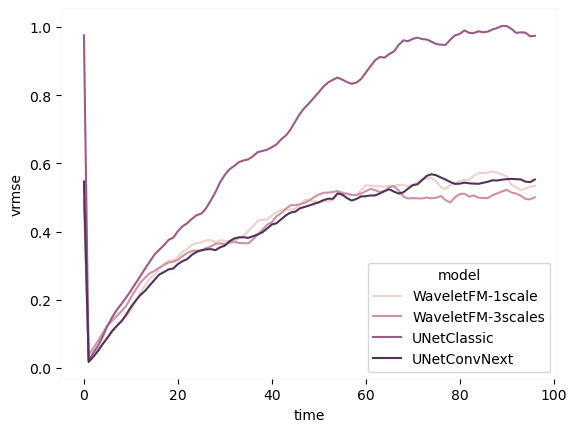

In [117]:
import seaborn as sb

aggregate=np.mean

table = df[df["field"] == field_name].copy()
palette = sb.cubehelix_palette(len(table["model"].unique()), dark=0.25)

sb.lineplot(table, x="time", y=f"vrmse",
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=None)


plt.show()

In [87]:
"""
# ── Per-field mosaic plots ────────────────────────────────────────────────────
for field in field_names:
    fig = plot_metrics(df, field_name=field, models_order=models_to_plot)
    fig.savefig(f"metrics_{field}.pdf", dpi=300, transparent=True, bbox_inches="tight")
    plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .median()
    .round(4)
)
print(summary.to_string())
"""

'\n# ── Per-field mosaic plots ────────────────────────────────────────────────────\nfor field in field_names:\n    fig = plot_metrics(df, field_name=field, models_order=models_to_plot)\n    fig.savefig(f"metrics_{field}.pdf", dpi=300, transparent=True, bbox_inches="tight")\n    plt.show()\n\n# ── Summary table ─────────────────────────────────────────────────────────────\nsummary = (\n    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]\n    .median()\n    .round(4)\n)\nprint(summary.to_string())\n'


PS-RMSE (density) — mean over lead times

band                  low     mid        high
model                                        
UNetClassic        0.9091  0.8592      2.1573
UNetConvNext       0.3559  0.1851      3.0429
WaveletFM-1scale   0.2689  0.4118   3308.3111
WaveletFM-3scales  0.1692  0.1903  16598.6501


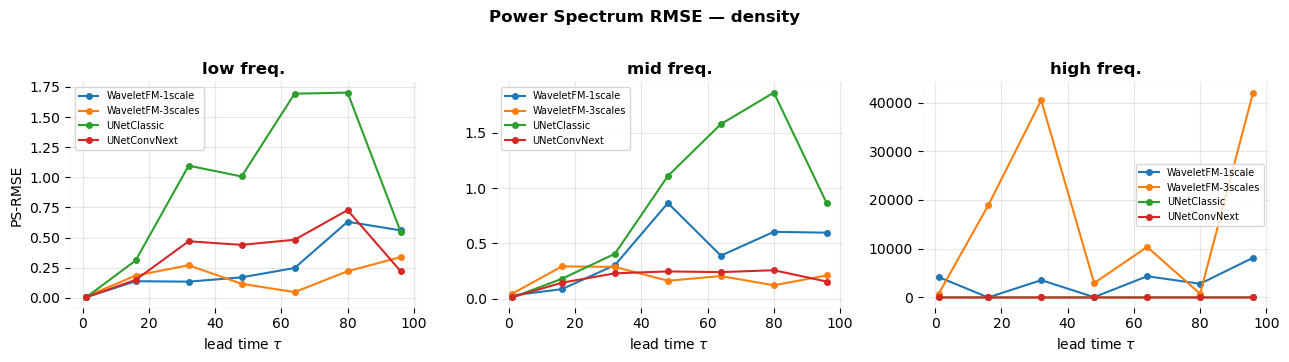

In [78]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from waveletflux.utils.fourier import isotropic_power_spectrum


def power_spectrum_rmse(
    u: torch.Tensor,           # ground-truth  (..., H, W)
    v: torch.Tensor,           # prediction    (..., H, W)
    n_bands: int = 3,
    spatial: int = 2,
    eps: float = 1e-8,
) -> tuple[torch.Tensor, list[str]]:
    """
    Computes the Power Spectrum RMSE (PS-RMSE) over log-spaced frequency bands.

    For each band, reports RMSE of the relative spectrum pv/pu around 1
    (perfect match = 0).

    Args:
        u        : Ground-truth field, shape (..., H, W)
        v        : Predicted field,    shape (..., H, W)
        n_bands  : Number of frequency bands (default 3: low / mid / high)
        spatial  : Number of spatial dimensions
        eps      : Stabiliser for division by near-zero GT power

    Returns:
        rmse_bands : Tensor of shape (..., n_bands)
        band_names : List of n_bands label strings
    """
    u = torch.as_tensor(u, dtype=torch.float32)
    v = torch.as_tensor(v, dtype=torch.float32)

    # p_*: (..., B),  freqs: (B,)  — linearly spaced in frequency space
    p_u, freqs = isotropic_power_spectrum(u, spatial=spatial)
    p_v, _     = isotropic_power_spectrum(v, spatial=spatial)

    # Relative power spectrum  (..., B)
    ratio = p_v / (p_u + eps)

    # ── Log-spaced band edges ──────────────────────────────────────────────────
    # freqs start slightly above 0; clamp to avoid log(0)
    log_f    = torch.log(freqs.clamp(min=1e-8))
    edges    = torch.linspace(log_f[0], log_f[-1], n_bands + 1)
    labels   = ["low", "mid", "high"][:n_bands]

    rmse_bands = []
    for i in range(n_bands):
        lo, hi = edges[i], edges[i + 1]
        # Include the rightmost bin in the last band
        mask = (log_f >= lo) & (log_f <= hi if i == n_bands - 1 else log_f < hi)
        ratio_band = ratio[..., mask]                             # (..., K)
        rmse = torch.sqrt(torch.mean((ratio_band - 1.0) ** 2, dim=-1))  # (...)
        rmse_bands.append(rmse)

    return torch.stack(rmse_bands, dim=-1), labels   # (..., n_bands)


# ── Evaluate across all lead times and models ─────────────────────────────────

def evaluate_ps_rmse(
    gt_frames:     list,         # len = n_lead_times, each (H, W)
    model_frames:  dict,         # model_name -> list of (H, W)
    lead_times:    list,
    field_name:    str = "field",
) -> pd.DataFrame:
    """
    Returns a DataFrame with columns:
        model | lead_time | band | ps_rmse
    """
    records = []

    for t_idx, lead in enumerate(lead_times):
        u = torch.as_tensor(np.asarray(gt_frames[t_idx]), dtype=torch.float32)

        for model_name, frames in model_frames.items():
            v = torch.as_tensor(np.asarray(frames[t_idx]), dtype=torch.float32)

            rmse, band_names = power_spectrum_rmse(u, v)

            for band, val in zip(band_names, rmse.tolist()):
                records.append({
                    "model":     model_name,
                    "lead_time": lead,
                    "band":      band,
                    "ps_rmse":   val,
                })

    return pd.DataFrame(records)


# ── Run ────────────────────────────────────────────────────────────────────────
df = evaluate_ps_rmse(gt_frames, model_frames, lead_times, field_name=field_name)

# ── Summary table (mean over lead times) ──────────────────────────────────────
summary = (
    df.groupby(["model", "band"])["ps_rmse"]
    .mean()
    .unstack("band")[["low", "mid", "high"]]   # enforce band order
    .round(4)
)
print(f"\nPS-RMSE ({field_name}) — mean over lead times\n")
print(summary.to_string())

# ── Plot: PS-RMSE vs lead time, one panel per band ────────────────────────────
band_names = ["low", "mid", "high"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=False)

colors = plt.cm.tab10.colors

for ax, band in zip(axes, band_names):
    sub = df[df["band"] == band]
    for ci, model in enumerate(models_to_plot):
        row = sub[sub["model"] == model]
        ax.plot(row["lead_time"], row["ps_rmse"],
                marker="o", markersize=4,
                label=model, color=colors[ci])
    ax.set_title(f"{band} freq.", fontweight="bold")
    ax.set_xlabel(r"lead time $\tau$")
    ax.set_ylabel("PS-RMSE" if band == "low" else "")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Power Spectrum RMSE — {field_name}", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

In [ ]:



# ══════════════════════════════════════════════════════════════════════════════
# Plotting
# ══════════════════════════════════════════════════════════════════════════════

def plot_metrics(
    df:           pd.DataFrame,
    field_name:   str,
    models_order: list[str] | None = None,
    aggregate=np.median,
) -> plt.Figure:
    """
    Mosaic plot: VRMSE + Spread/Skill on the left, PS-RMSE bands on the right.
    Mirrors the reference plotting style.
    """
    table = df[df["field"] == field_name].copy()
    if models_order:
        table["model"] = pd.Categorical(table["model"], categories=models_order, ordered=True)

    palette = sb.cubehelix_palette(len(table["model"].unique()), dark=0.25)

    fig, axs = plt.subplot_mosaic(
        [[0, 2], [0, 2], [0, 3], [1, 3], [1, 4], [1, 4]],
        figsize=(6.4, 3.2),
        sharex=True,
        sharey=False,
    )

    # ── Left: VRMSE and Spread/Skill ──────────────────────────────────────────
    for i, (metric, ylabel) in enumerate([("vrmse", "VRMSE"), ("spread_skill", "Spread / Skill")]):
        ax = sb.lineplot(
            table, x="time", y=metric,
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=axs[i],
        )
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.set_xlabel("Lead time")
        ax.set_ylabel(ylabel)
        ax.tick_params(direction="in")

    handles, labels = axs[0].get_legend_handles_labels()

    # ── Right: PS-RMSE per band ───────────────────────────────────────────────
    for i, band in enumerate(["low", "mid", "high"], start=2):
        ax = sb.lineplot(
            table, x="time", y=f"rmse_p_{band}",
            hue="model", estimator=aggregate, errorbar=None,
            palette=palette, ax=axs[i],
        )
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.set_xlabel("Lead time")
        ax.set_ylabel(band.capitalize())
        ax.tick_params(direction="in")
        ax.yaxis.set_label_position("right")
        ax.yaxis.label.set(rotation=-90, va="center")
        ax.yaxis.tick_right()
        if i == 2:
            ax.set_title("Power Spectrum RMSE")

    # ── Shared legend ─────────────────────────────────────────────────────────
    fig.align_labels()
    fig.tight_layout(pad=0.33)
    fig.subplots_adjust(top=0.875)
    fig.legend(handles, labels, loc="upper left", ncol=len(labels))
    fig.suptitle(field_name, x=0.5, y=0.98)

    return fig

In [81]:
df

,model,traj,field,lead_time,time,m1,m2,spread,rmse,nrmse,vrmse,spread_skill,total_error,rmse_p_low,rmse_c_low,rmse_p_mid,rmse_c_mid,rmse_p_high,rmse_c_high
0,WaveletFM-1scale,0,density,1,1,34.000000,3331.937500,NaN,8.083933,0.140047,0.173299,NaN,-0.006833,0.040269,0.010163,0.047816,0.323989,0.229029,0.299202
1,WaveletFM-1scale,0,density,16,16,34.226631,3084.069092,NaN,15.453472,0.278268,0.353353,NaN,-0.011672,0.263862,0.046675,0.114056,0.133412,0.092571,0.087277
2,WaveletFM-1scale,0,density,32,32,34.680264,3223.936768,NaN,20.294727,0.357429,0.451411,NaN,-0.002949,0.310172,0.097632,0.135504,0.168295,0.183992,0.092003
3,WaveletFM-1scale,0,density,48,48,35.334240,2903.990967,NaN,14.342299,0.266147,0.352494,NaN,-0.015698,0.079050,0.058557,0.238771,0.143611,0.106542,0.115983
4,WaveletFM-1scale,0,density,64,64,36.284016,3005.396484,NaN,23.284973,0.424742,0.566596,NaN,-0.002273,0.208492,0.204687,0.448679,0.169005,0.311442,0.112462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1003,UNetConvNext,8,velocity_y,32,32,-0.002883,0.000030,NaN,0.008507,1.525704,1.782508,NaN,-0.830927,5.144621,0.137835,0.976730,0.189901,0.283631,0.111387
1004,UNetConvNext,8,velocity_y,48,48,-0.004402,0.000046,NaN,0.012157,1.767425,2.299994,NaN,-0.187898,9.555409,0.171031,1.263859,0.161897,0.076900,0.143787
1005,UNetConvNext,8,velocity_y,64,64,-0.005096,0.000069,NaN,0.012065,1.446053,1.826279,NaN,-0.192884,2.475294,0.149107,1.622862,0.231892,0.113371,0.158813
1006,UNetConvNext,8,velocity_y,80,80,-0.003842,0.000041,NaN,0.008574,1.324861,1.646336,NaN,0.061753,1.323830,0.184991,0.362526,0.164274,0.099973,0.118590


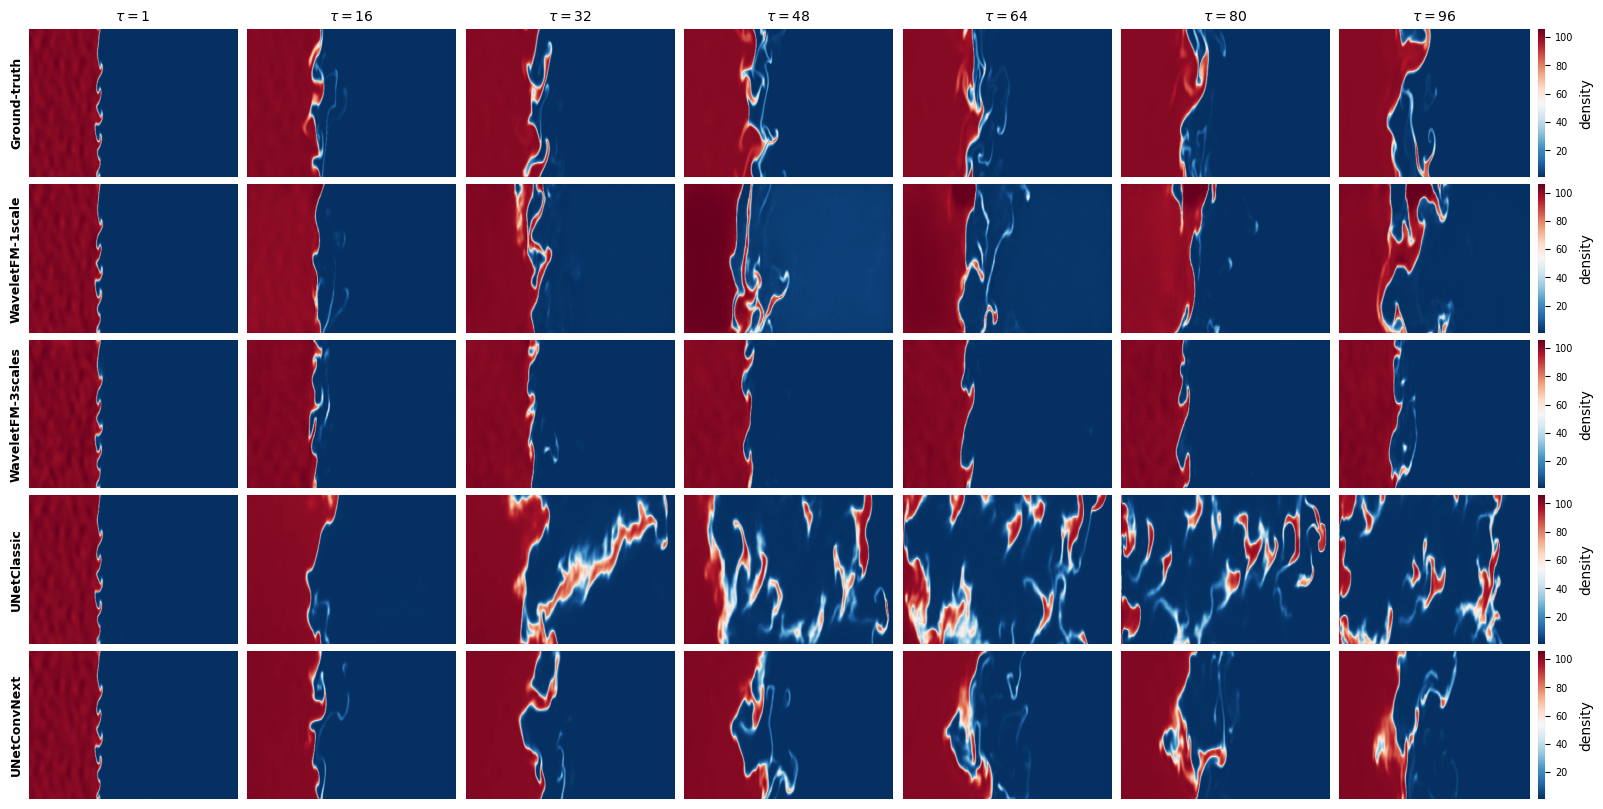

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from waveletflux.utils.plot import field2rgb

models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales", "UNetClassic", "UNetConvNext"]
field_names    = ['density', 'pressure', 'velocity_x', 'velocity_y']

TRAJ_IDX   = 8
ENS_IDX    = 0
Ti         = 4
field_idx  = 0
field_name = field_names[field_idx]
lead_times = [1, 16, 32, 48, 64, 80, 96]

def get_gt_frame(tensor, traj_idx, lead, field):
    return tensor[traj_idx, Ti + lead - 1, :, :, field]

def get_pred_frame(tensor, traj_idx, ens_idx, lead, field):
    if len(tensor.shape) == 6:
        return tensor[traj_idx, ens_idx, lead - 1, :, :, field]
    return tensor[traj_idx, lead - 1, :, :, field]

gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot
}

row_labels     = ["Ground-truth"] + models_to_plot
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot]
n_rows, n_cols = len(row_labels), len(lead_times)

# ── Compute shared vmin/vmax from ground-truth frames ─────────────────────────
vmin = float(min(f.min() for f in gt_frames))
vmax = float(max(f.max() for f in gt_frames))

# ── Convert all frames to RGB up-front ────────────────────────────────────────
# field2rgb expects any array shape; contrast=1.5 is the default
rgb_rows = [
    [field2rgb(frame, vmin=vmin, vmax=vmax, cmap="RdBu_r") for frame in row]
    for row in all_row_frames
]

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.8 * n_cols, 2.0 * n_rows),
    gridspec_kw={"hspace": 0.05, "wspace": 0.05},
)
if n_rows == 1:
    axes = axes[None, :]

plt.rcParams["axes.linewidth"] = 0.02

for ri, (rgb_frames, label) in enumerate(zip(rgb_rows, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        # field2rgb already returns uint8 RGB — no cmap/vmin/vmax needed here
        ax.imshow(rgb_frames[ci], origin="lower", aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=10, fontweight="bold")

    # Colorbar: build a ScalarMappable since we no longer have an imshow handle
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    sm = cm.ScalarMappable(norm=mcolors.Normalize(vmin=vmin, vmax=vmax), cmap="RdBu_r")
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    cbar.ax.tick_params(labelsize=7)

plt.show()